# OptiStock IA - Modélisation Prédictive & Optimisation des Stocks (Carrefour)

Ce notebook présente l'implémentation complète, commentée et industrialisable de la solution d'intelligence artificielle **OptiStock IA** développée pour Carrefour.

### Sommaire du Notebook :
1. **Configuration de l'environnement et imports des librairies**
2. **Chargement et inspection des données transactionnelles**
3. **Analyse exploratoire : Matrice de corrélation linéaire**
4. **Ingénierie des variables (Feature Engineering & One-Hot Encoding)**
5. **Découpage temporel chronologique (70% Train / 30% Test)**
6. **Création et entraînement du modèle Random Forest Regressor**
7. **Sauvegarde et sérialisation du modèle entraîné (Joblib)**
8. **Évaluation détaillée des métriques de performance (R², MAPE, RMSE, MAE)**
9. **Analyse de l'importance des variables explicatives (Feature Importance)**
10. **Simulation opérationnelle : Moteur de réassort automatique sur PDA magasin**

In [1]:
# =============================================================================
# 1. CONFIGURATION ET CHARGEMENT DES BIBLIOTHÈQUES
# =============================================================================
import os
import joblib  # Pour la sérialisation et la persistance du modèle IA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modules d'apprentissage supervisé et métriques d'évaluation Scikit-Learn
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
    mean_absolute_error
)

# Configuration de la charte graphique des visualisations
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("[OK] Bibliothèques importées avec succès.")

[OK] Bibliothèques importées avec succès.


## 2. Chargement et Exploration des Données
Nous chargeons l'historique transactionnel consolidé (`carrefour_sales_inventory_dataset.csv`) et nous isolons le **magasin pilote de Paris Auteuil (`FR_PARIS_HYPER_01`)**.

In [2]:
# =============================================================================
# 2. CHARGEMENT ET FILTRAGE DU JEU DE DONNÉES
# =============================================================================
# Lecture du fichier CSV consolidé issu de l'entrepôt de données
df = pd.read_csv('carrefour_sales_inventory_dataset.csv')

# Filtrage sur le point de vente pilote (Hypermarché Paris Auteuil)
df_pilot = df[df['store_id'] == 'FR_PARIS_HYPER_01'].copy()

# Conversion de la colonne date en type datetime et tri chronologique strict
df_pilot['date_ticket'] = pd.to_datetime(df_pilot['date_ticket'])
df_pilot = df_pilot.sort_values('date_ticket').reset_index(drop=True)

print(f"[INFO] Données du magasin pilote : {df_pilot.shape[0]} lignes et {df_pilot.shape[1]} colonnes.")
df_pilot[['date_ticket', 'product_name', 'category', 'unit_price_eur', 'is_promo', 'temperature_celsius', 'quantity_sold', 'stock_available']].head()

[INFO] Données du magasin pilote : 10965 lignes et 19 colonnes.


,date_ticket,product_name,category,unit_price_eur,is_promo,temperature_celsius,quantity_sold,stock_available
0,2024-01-01,Lait Demi-Écrémé 1L Carrefour Bio,Crémerie,1.25,0,0.6,270,444
1,2024-01-01,Yaourts Nature x8 Carrefour,Crémerie,2.10,0,0.6,172,190
2,2024-01-01,Filet de Poulet Fermier 500g Carrefour,Boucherie,6.20,0,0.6,99,95
3,2024-01-01,Eau Minérale Naturelle 6x1.5L Carrefour,Boissons,1.44,1,0.6,226,328
4,2024-01-01,Jambon Supérieur x4 Carrefour Bio,Charcuterie,3.40,0,0.6,117,119


## 3. Analyse Exploratoire : Matrice de Corrélation Linéaire
Étude des corrélations de Pearson entre les variables contextuelles (météo, prix, promo, calendrier) et les volumes de vente réels.

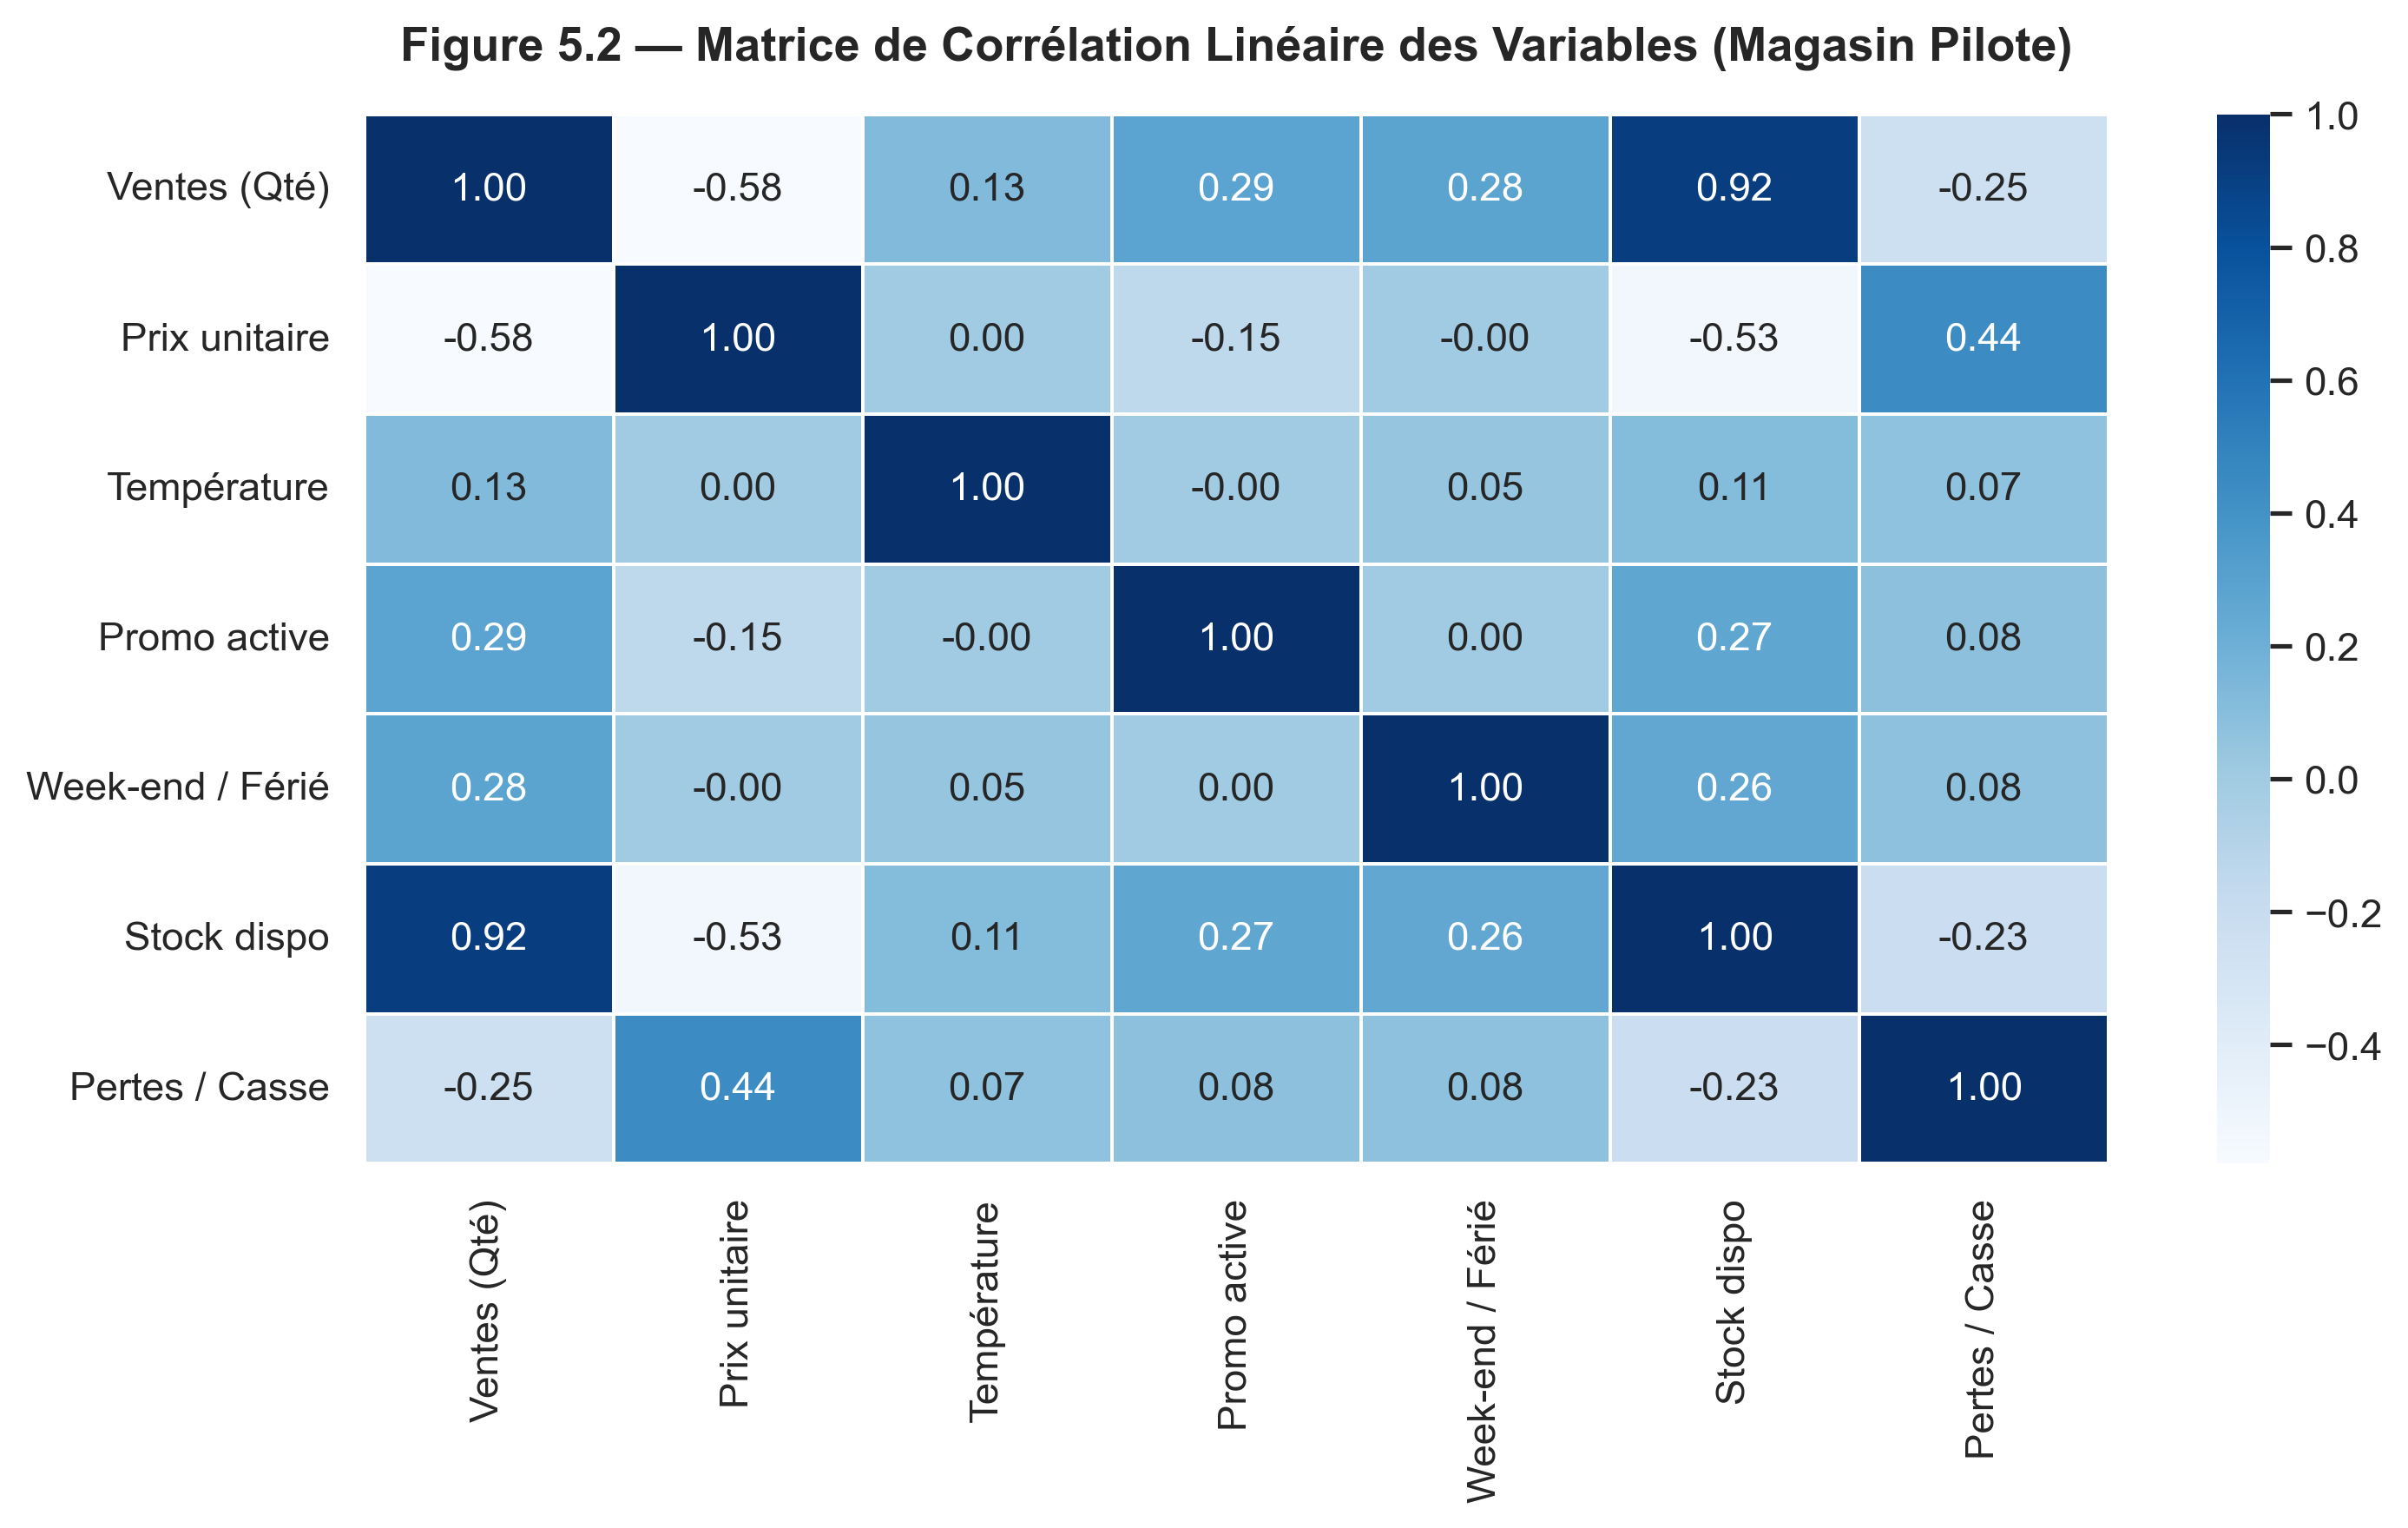

In [3]:
# =============================================================================
# 3. MATRICE DE CORRÉLATION DE PEARSON
# =============================================================================
# Sélection des variables quantitatives d'intérêt
num_cols = [
    'quantity_sold', 'unit_price_eur', 'temperature_celsius', 
    'is_promo', 'is_holiday_or_weekend', 'stock_available', 'waste_units'
]
labels = [
    'Ventes (Qté)', 'Prix unitaire', 'Température', 
    'Promo active', 'Week-end / Férié', 'Stock dispo', 'Pertes / Casse'
]

# Calcul de la matrice de corrélation linéaire
corr_matrix = df_pilot[num_cols].corr()

# Affichage de la carte thermique (Heatmap)
plt.figure(figsize=(10, 6), dpi=300)
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap='Blues', 
    xticklabels=labels, 
    yticklabels=labels, 
    cbar=True,
    linewidths=0.5
)
plt.title('Figure 5.2 — Matrice de Corrélation Linéaire des Variables (Magasin Pilote)', fontsize=13, weight='bold', pad=15)
plt.tight_layout()
plt.show()

## 4. Préparation des Données & Feature Engineering
Transformation des variables catégorielles par encodage One-Hot et constitution de la matrice des variables d'apprentissage ($X$) et de la cible ($y$).

In [4]:
# =============================================================================
# 4. ENCODAGE ET PRÉPARATION DES MATRICES D'ENTRÉE
# =============================================================================
# Encodage One-Hot des variables catégorielles (rayon et référence SKU)
df_encoded = pd.get_dummies(df_pilot, columns=['category', 'sku_id'], drop_first=True)

# Exclusion des identifiants, métadonnées textuelles et variables cibles/post-ventes
drop_cols = [
    'transaction_id', 'date_ticket', 'store_id', 'store_name', 'store_format',
    'store_region', 'product_name', 'quantity_sold', 'stock_available',
    'waste_units', 'out_of_stock_risk', 'shelf_life_days'
]
features = [col for col in df_encoded.columns if col not in drop_cols]

# Matrice des descripteurs X et vecteur cible y
X = df_encoded[features]
y = df_encoded['quantity_sold']

print(f"[INFO] Matrice X préparée : {X.shape[0]} lignes x {X.shape[1]} variables explicatives.")

[INFO] Matrice X préparée : 10965 lignes x 26 variables explicatives.


## 5. Découpage (70% Train / 30% Test)
emporel.

In [ ]:
# =============================================================================
# 5. DÉCOUPAGE STRICT
# =============================================================================
# Détermination de l'indice de coupure à 70%
split_idx = int(len(df_encoded) * 0.7)

# Scission des données d'entraînement et de test
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

date_split = df_pilot.loc[split_idx, 'date_ticket'].strftime('%d/%m/%Y')
print(f"[INFO] Date de bascule Train -> Test : {date_split}")
print(f"[INFO] Échantillons Train (70%) : {len(X_train)} observations")
print(f"[INFO] Échantillons Test (30%)  : {len(X_test)} observations")

[INFO] Date de bascule Train -> Test : 26/05/2025
[INFO] Échantillons Train (70%) : 7675 observations
[INFO] Échantillons Test (30%)  : 3290 observations


## 6. Création et Entraînement du Modèle Random Forest

In [6]:
# =============================================================================
# 6. INSTANCIATION ET ENTRAÎNEMENT DU MODÈLE
# =============================================================================
# Random Forest Regressor avec hyperparamètres contrôlés
rf_model = RandomForestRegressor(
    n_estimators=100,       # 100 arbres de décision pour une bonne convergence
    max_depth=12,          # Profondeur max pour limiter le surapprentissage
    min_samples_split=4,   # Nombre min d'échantillons pour scinder un nœud
    random_state=42,       # Graine aléatoire fixée pour garantir la reproductibilité
    n_jobs=-1              # Utilisation de tous les cœurs CPU disponibles
)

# Phase d'apprentissage supervisé sur le set d'entraînement
rf_model.fit(X_train, y_train)
print("[OK] Modèle RandomForestRegressor entraîné avec succès.")

[OK] Modèle RandomForestRegressor entraîné avec succès.


## 7. Sauvegarde et Sérialisation du Modèle (`joblib`)
Pour permettre l'industrialisation (MLOps) et le déploiement sur l'API ou les PDA magasins, nous enregistrons le modèle et la liste ordonnée des variables.

In [7]:
# =============================================================================
# 7. SÉRIALISATION DU MODÈLE ET DES MÉTADONNÉES
# =============================================================================
model_artifacts = {
    'model': rf_model,
    'features': features,
    'store_id': 'FR_PARIS_HYPER_01',
    'algorithm': 'RandomForestRegressor',
    'target': 'quantity_sold'
}

# Sauvegarde du fichier binaire optimisé
model_filename = 'optistock_rf_model.joblib'
joblib.dump(model_artifacts, model_filename)

print(f"[OK] Modèle et métadonnées sauvegardés avec succès sous : {model_filename}")
print(f"[INFO] Taille du fichier sérialisé : {os.path.getsize(model_filename) / (1024*1024):.2f} Mo")

[OK] Modèle et métadonnées sauvegardés avec succès sous : optistock_rf_model.joblib
[INFO] Taille du fichier sérialisé : 14.12 Mo


## 8. Évaluation Détaillée des Performances sur le Jeu de Test

In [8]:
# =============================================================================
# 8. CALCUL DES MÉTRIQUES D'ÉVALUATION SUR LES DONNÉES DE TEST
# =============================================================================
# Génération des prédictions sur le jeu de test non vu
y_pred = rf_model.predict(X_test)

# Calcul des métriques de précision
r2 = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("=" * 60)
print(" BILAN DE PERFORMANCE - OPTISTOCK IA (TEST SET 30%)")
print("=" * 60)
print(f"Coefficient de Détermination (R²)    : {r2:.4f} (Objectif > 0.90)")
print(f"Erreur Absolue Moyenne % (MAPE)      : {mape:.2f} % (Objectif < 8.00 %)")
print(f"Erreur Quadratique Moyenne (RMSE)     : {rmse:.2f} unités")
print(f"Erreur Absolue Moyenne (MAE)         : {mae:.2f} unités")
print("=" * 60)

 BILAN DE PERFORMANCE - OPTISTOCK IA (TEST SET 30%)
Coefficient de Détermination (R²)    : 0.9644 (Objectif > 0.90)
Erreur Absolue Moyenne % (MAPE)      : 7.32 % (Objectif < 8.00 %)
Erreur Quadratique Moyenne (RMSE)     : 12.93 unités
Erreur Absolue Moyenne (MAE)         : 9.10 unités


In [ ]:
# =============================================================================
# VISUALISATION TEMPORELLE : VENTES RÉELLES VS PRÉDICTIONS IA
# =============================================================================
test_subset = df_pilot.iloc[split_idx:].copy()
sample_sku = test_subset[test_subset['product_name'].str.contains('Bière')].head(60)
sample_idx = sample_sku.index

plt.figure(figsize=(14, 6))
plt.plot(df_pilot.loc[sample_idx, 'date_ticket'], df_pilot.loc[sample_idx, 'quantity_sold'], 
         label='Ventes Réelles (Magasin)', color='#004f9f', marker='o', lw=2.2)
plt.plot(df_pilot.loc[sample_idx, 'date_ticket'], rf_model.predict(X.loc[sample_idx]), 
         label='Prédictions OptiStock IA', color='#e05a47', linestyle='--', lw=2.2)

plt.title('Figure 5.3 — Validation Temporelle : Ventes Réelles vs Prédictions IA (Bière Blonde)', fontsize=13, weight='bold')
plt.xlabel('Date')
plt.ylabel('Unités vendues')
plt.xticks(rotation=30)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 9. Importance des Variables Explicatives (Feature Importance)

C:\Users\PC\AppData\Local\Temp\ipykernel_28488\102875071.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_importances.values, y=feat_importances.index, palette='Blues_r')


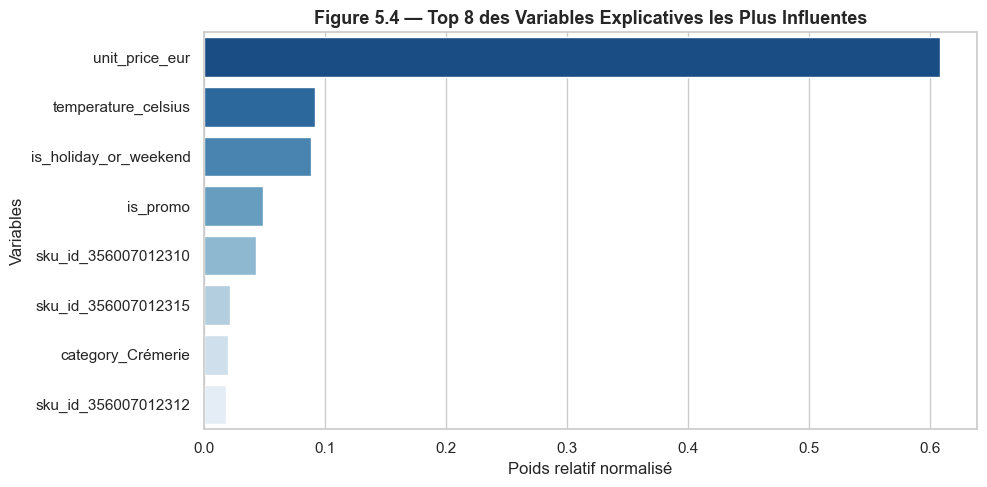

In [9]:
# =============================================================================
# 9. ANALYSE DU POIDS RELATIF DES DESCRIPTEURS DANS LA DÉCISION
# =============================================================================
feat_importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False).head(8)

plt.figure(figsize=(10, 5))
sns.barplot(x=feat_importances.values, y=feat_importances.index, palette='Blues_r')
plt.title('Figure 5.4 — Top 8 des Variables Explicatives les Plus Influentes', fontsize=13, weight='bold')
plt.xlabel('Poids relatif normalisé')
plt.ylabel('Variables')
plt.tight_layout()
plt.show()

## 10. Simulation Opérationnelle : Moteur de Réassort Automatique (PDA)
Fonction métier rechargeant le modèle sauvegardé pour émettre une recommandation de réassort quotidienne à destination des chefs de rayon.

In [10]:
# =============================================================================
# 10. MOTEUR DE RECOMMANDATION DE COMMANDE POUR PDA MAGASIN
# =============================================================================
def calculer_reassort_quotidien(sku_name, date_str, temp_celsius, is_promo_active, is_weekend, stock_actuel, stock_securite=15):
    """
    Charge le modèle sérialisé et calcule la quantité optimale à commander.
    
    Paramètres :
    - sku_name (str) : Nom ou mot-clé du produit ciblé
    - date_str (str) : Date ciblée pour la livraison
    - temp_celsius (float) : Température prévue (°C)
    - is_promo_active (bool) : Statut de la promotion
    - is_weekend (bool) : Indicateur week-end / jour férié
    - stock_actuel (int) : Stock physique compté en rayon
    - stock_securite (int) : Marge tampon pour éviter les ruptures imprévues
    """
    # 1. Chargement du modèle sérialisé
    artifacts = joblib.load('optistock_rf_model.joblib')
    loaded_model = artifacts['model']
    model_features = artifacts['features']
    
    # 2. Identification du produit dans le catalogue
    matching_rows = df_pilot[df_pilot['product_name'].str.contains(sku_name, case=False, na=False)]
    if matching_rows.empty:
        return f"Erreur : Produit '{sku_name}' non identifié dans le catalogue."
    
    sample_row = matching_rows.iloc[0]
    sku_id = sample_row['sku_id']
    category = sample_row['category']
    unit_price = sample_row['unit_price_eur']
    
    # 3. Construction du vecteur de caractéristiques pour l'inférence
    input_dict = {col: 0 for col in model_features}
    input_dict['unit_price_eur'] = unit_price
    input_dict['is_promo'] = 1 if is_promo_active else 0
    input_dict['temperature_celsius'] = temp_celsius
    input_dict['is_rainy'] = 0
    input_dict['is_holiday_or_weekend'] = 1 if is_weekend else 0
    
    # Activation des indicateurs catégoriels One-Hot
    cat_col = f"category_{category}"
    if cat_col in input_dict:
        input_dict[cat_col] = 1
        
    sku_col = f"sku_id_{sku_id}"
    if sku_col in input_dict:
        input_dict[sku_col] = 1
        
    # Inférence
    X_input = pd.DataFrame([input_dict])
    predicted_demand = int(np.round(loaded_model.predict(X_input)[0]))
    
    # 4. Calcul de réapprovisionnement net
    reassort_conseille = max(0, (predicted_demand + stock_securite) - stock_actuel)
    
    # 5. Affichage formaté type terminal PDA
    print("=" * 65)
    print(f" FICHE DE COMMANDE SUGGÉRÉE - TERMINAL PDA CARREFOUR")
    print("=" * 65)
    print(f"Produit              : {sample_row['product_name']}")
    print(f"Rayon                : {category}")
    print(f"Date ciblée          : {date_str} (Météo : {temp_celsius}°C, Promo : {is_promo_active})")
    print(f"Stock physique actuel: {stock_actuel} unités")
    print(f"Demande prévue (IA)  : {predicted_demand} unités")
    print(f"Stock de sécurité    : {stock_securite} unités")
    print("-" * 65)
    print(f">>> QUANTITÉ NETTE À COMMANDER : {reassort_conseille} unités <<<")
    print("=" * 65)

# Simulation d'inférence en conditions réelles (Samedi estival ensoleillé)
calculer_reassort_quotidien(
    sku_name="Bière",
    date_str="22/08/2026",
    temp_celsius=29.5,
    is_promo_active=True,
    is_weekend=True,
    stock_actuel=35,
    stock_securite=15
)

 FICHE DE COMMANDE SUGGÉRÉE - TERMINAL PDA CARREFOUR
Produit              : Bière Blonde 6x25cl Carrefour
Rayon                : Boissons
Date ciblée          : 22/08/2026 (Météo : 29.5°C, Promo : True)
Stock physique actuel: 35 unités
Demande prévue (IA)  : 230 unités
Stock de sécurité    : 15 unités
-----------------------------------------------------------------
>>> QUANTITÉ NETTE À COMMANDER : 210 unités <<<
